# Inverse components

```mermaid
graph TD
    %% Styling
    classDef step fill:#f9f,stroke:#333,stroke-width:2px,rx:10,ry:10,color:#000;
    classDef object fill:#fff,stroke:#333,stroke-width:1px,color:#000;
    classDef proof fill:#ffeb3b,stroke:#fbc02d,stroke-width:3px,color:#000;

    subgraph Input_Data [Input Data]
        Y[("Sensor Data")]:::object
        C[("Noise Covariance")]:::object
        G[("Forward Matrix")]:::object
        Con[("Connectome")]:::object
    end

    subgraph Preprocessing [1. Preprocessing]
        AVG_step[[Average Referencing]]:::step
        
        Y --> AVG_step
        C --> AVG_step
        G --> AVG_step
        
        Y_ref["Ref Data"]:::object
        C_ref["Ref Cov"]:::object
        G_ref["Ref Forward"]:::object
        
        AVG_step --> Y_ref
        AVG_step --> C_ref
        AVG_step --> G_ref

        W_calc[[Compute Whitener]]:::step
        C_ref --> W_calc

        Y_white["Whitened Data"]:::proof
        W_calc --> Y_white
        Y_ref --> Y_white

        G_white["Whitened Forward"]:::proof
        W_calc --> G_white
        G_ref --> G_white
    end

    subgraph Source_Priors [2. Source Priors]
        Depth_step[[Depth weighting]]:::step
        G_white --> Depth_step

        Prior_gft[[Graph Fourier Transform]]:::step
        Con --> Prior_gft
        
        Prior_harm[[Harmonic weighting]]:::step
        Con --> Prior_harm

        Prior["Combined Prior"]:::object
        Depth_step --> Prior
        Prior_gft --> Prior
        Prior_harm --> Prior

        G_prior["Adjusted Forward"]:::object
        Prior --> G_prior
        G_white --> Prior
    end

    subgraph Inverse [3. Inverse Logic]
        SVD_step[[SVD Decomposition]]:::step
        G_prior --> SVD_step
        
        Kernel["Inverse Kernel"]:::object
        SVD_step --> Kernel

        Sol_step[[Apply Kernel]]:::step
        Kernel --> Sol_step
        Y_white --> Sol_step

        Sol["Source Estimate"]:::object
        Sol_step --> Sol
    end

    subgraph Normalization [4. Normalization]
        Norm_step[[Compute Norm Factors]]:::step
        Kernel --> Norm_step
        
        Final["Final Activity"]:::object
        Sol --> Final
        Norm_step --> Final
    end
```

As illustrated in the diagram above, the system consists of many components! Because most are implemented from scratch, we will produce validation plots for the components highlighted in yellow to ensure they behave as expected.

## 🧪 - Experiment setup
- `fwd`: Forward solution
- `ave`: Measurements
- `ncov`: Noise covariance

In [1]:
# imports
import mindmap as mm
import mne
import matplotlib.pyplot as plt
import numpy as np

# readers
dm = mm.io.TutoManager("../../config.yml")
sr = dm.get_subject("simf10")

# data
fwd = sr.load("fwd")
ave = sr.load("ave", task="rest", run="11")
ncov = sr.load("cov", task="rest", run="11")

## 🧬 - Data Processing
Build components of interest

In [2]:
# instanciate inverse object
inv = mm.analysis.inverse.MNE(fwd, ncov)

# compute preprocessed data (and store in mne objects)
proj_gain, proj_data, whitener = inv._setup_preprocessor(ave.info)

fwd_white = mne.convert_forward_solution(fwd, force_fixed=True, copy=True)
fwd_white["sol"]["data"] = whitener @ proj_gain @ inv.gain_raw


    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


## 📊 - Visualization
### 1. Verify whitener

Whitened covariance should be a diagonal matrix.

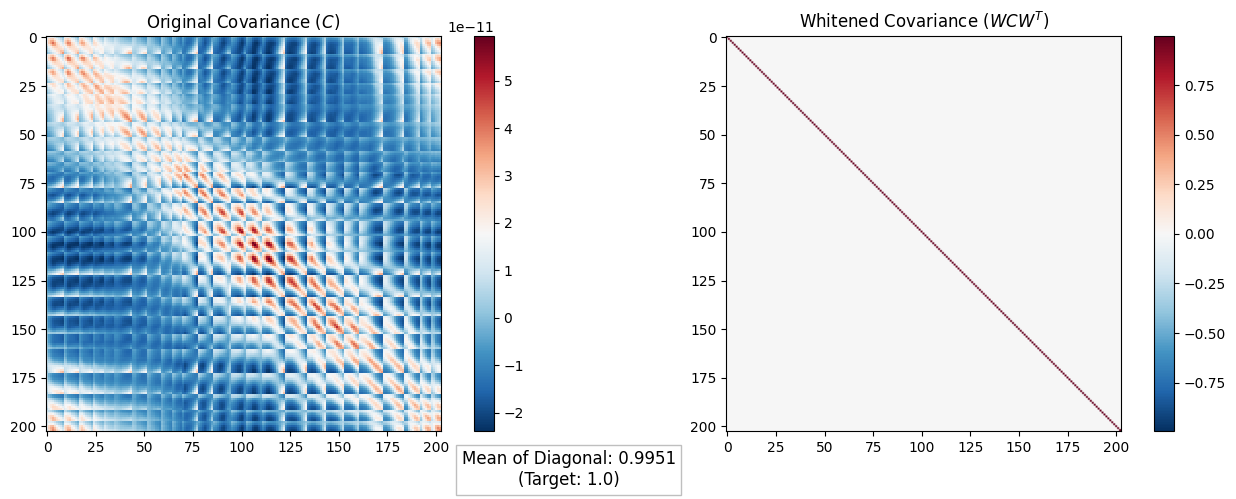

In [3]:
mm.viz.plot_whitened_cov(ncov, whitener)

#### 2. Verify processed data

Average referencing. Expectations, spatial average should be 0 at all times.

Projections have already been applied. Setting proj attribute to True.


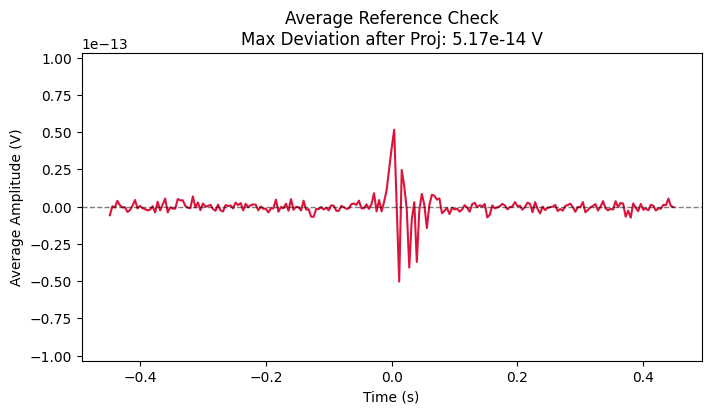

In [4]:
mm.viz.plot_avg_ref(ave, apply_proj=True)

Global field power. Expectations:
- During baseline (noise only): variance across channels should be approximately 1.0
- During signal (active brain): variance should be 1.0 + Signal power

Projections have already been applied. Setting proj attribute to True.
Whitened Baseline GFP: 1.1497 (Should be ~1.0)


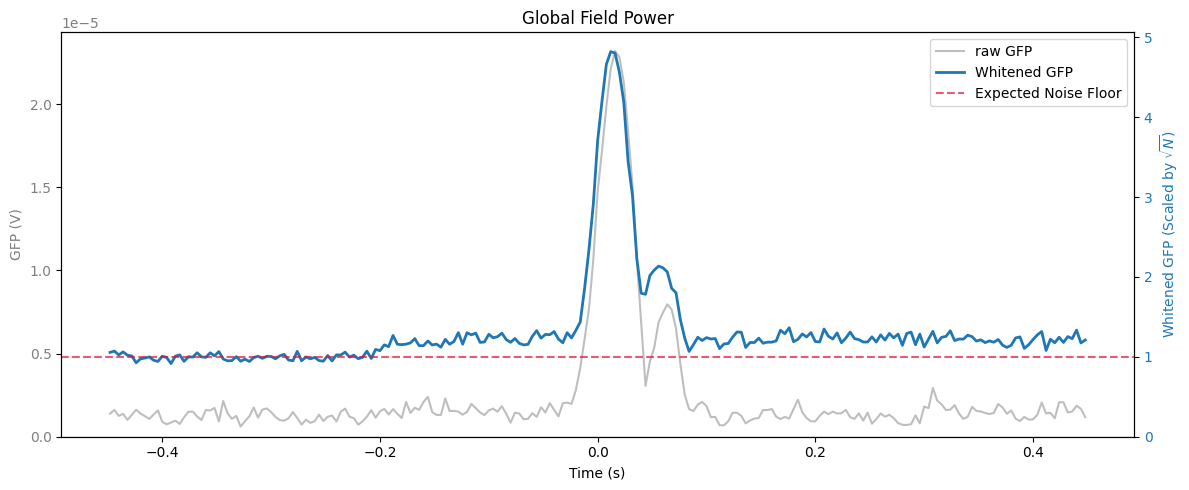

In [5]:
mm.viz.plot_gfp(ave.copy().apply_proj(), whitener)

#### 3. Verify whitened forward matrix


Average referencing. Expectations: Column averages are close to zero.

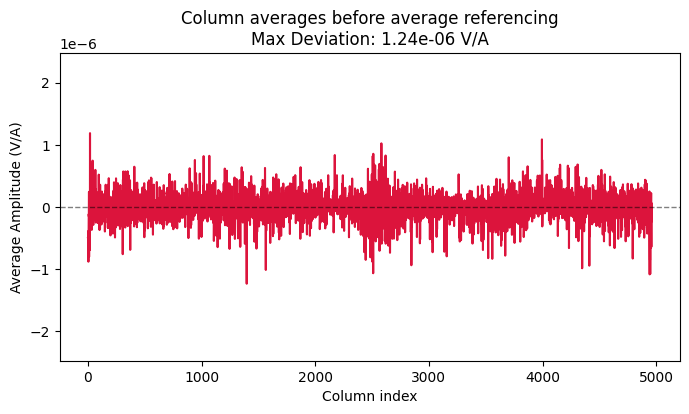

In [6]:
mm.viz.plot_fwd_avg_ref(fwd_white, title="Column averages before average referencing", fixed=False)

Whitening (& weighting). Expectation: More stable forward matrix (lower condition number - typically between 10 and 10³)

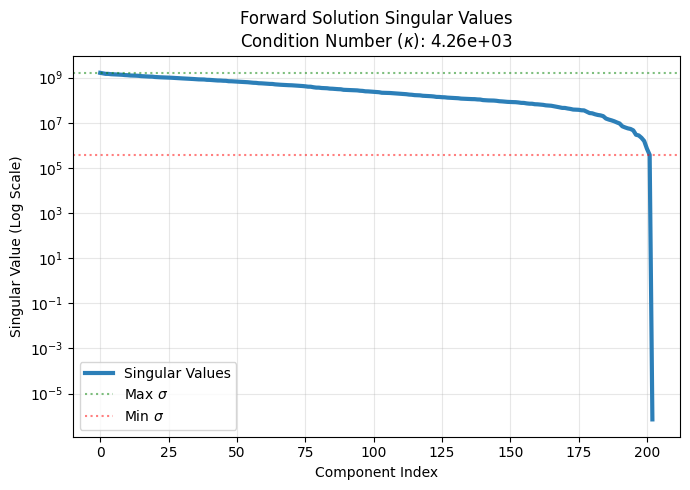

In [7]:
mm.viz.plot_fwd_singular_values(fwd_white, fixed=False)

In [ ]:
def plot_spatial_whitening(gain_raw, gain_white, title="Spatial Whitening"):
    """
    Plots the sensor-covariance (G @ G.T) to show whitening
    decorrelates the forward model sensors.
    """
    # Compute sensor correlations (Normalized Covariance)
    def get_corr(gain):
        cov = gain @ gain.T
        # Convert to correlation matrix for easier visual comparison (-1 to 1)
        d = np.sqrt(np.diag(cov))
        return cov / np.outer(d,d)
    
    corr_raw = get_corr(gain_raw)
    corr_white = get_corr(gain_white)

    # Build figure
    fig, axes = plt.subplots(1,2,figsize=(14,6))

    # plot raw
    im0 = axes[0].imshow(corr_raw, cmap="RdBu_r", vmin=-1, vmax=1)
    axes[0].set_title("Raw Sensor Correlation\n($G_{raw}^T$)")
    plt.colorbar(im0, ax=axes[0])

    # plot whitened
    im1 = axes[1].imshow(corr_white, cmap="RdBu_r", vmin=-1, vmax=1)
    axes[1].set_title("Whitened Sensor Correlation\n($G_{white} G_{white}^T$)")
    plt.colorbar(im1, ax=axes[1])

    for ax in axes:
        ax.set_xlabel("Sensor Index")
        ax.set_ylabel("Sensor Index")

    plt.suptitle(title, fontsize=16, fontweight="bold")
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])

    plt.close(fig)
    return fig

Trace Adjustment. Expectation: The diagonal average of GRG^T, where G is the gain matrix and R is the source covariance, should be close to 1.

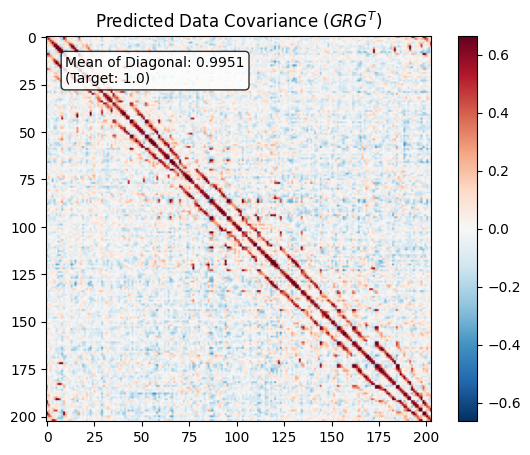

In [8]:
mm.viz.plot_predicted_data_covariance(inv, ave)

New forward sensitivity

In [8]:
mm.viz.plot_fwd_sensitivity(fwd_white, fixed=False, title="New forward sensitivity").show()

Widget(value='<iframe src="http://localhost:39383/index.html?ui=P_0x7b3c7657f950_0&reconnect=auto" class="pyvi…